# Mango Leaf Disease Classification with a CNN Built from Scratch

**Student:** MD MERAZ UDDIN  |  **ID:** 23-50322-1
**Course:** 01198 Computer Vision and Pattern Recognition [A], Fall 26-27

| Item | Value |
|---|---|
| Dataset | MLD24: An image dataset for mango leaf disease detection (Mendeley Data) [1] |
| Source | https://data.mendeley.com/datasets/6dvpywm2m2/1 (DOI 10.17632/6dvpywm2m2.1), CC BY 4.0 |
| Content | 6,400 RGB images, 8 classes (7 diseases and healthy), 800 per class, 240 x 240 px |

**Objective:** classify mango leaf images into 8 health conditions with a CNN implemented from scratch in PyTorch, compare it with a KNN baseline, and analyse its behaviour. All random operations use a fixed seed (42).

## 1. Setup

The dataset is read from the attached archive and all experiment settings are in the configuration cell.

In [2]:

DATASET_NAME = "MLD24 Mango Leaf Disease" 

DATA_DIR = "/content/dataset"            
import os
if os.path.exists("/kaggle/input"):                       
    _c = [d for d in os.listdir("/kaggle/input") if "mld" in d.lower() or "mango" in d.lower()]
    DATA_DIR = os.path.join("/kaggle/input", _c[0] if _c else "")
    DATA_ZIP = ""
else:                                                     
    from google.colab import drive; drive.mount('/content/drive')
    DATA_ZIP = "/content/drive/MyDrive/CVPR/MLD24.zip"   

CLASS_PARTS_INDEX = None   
                           

IMG_SIZE    = 128         
BATCH_SIZE  = 32
EPOCHS      = 25
LR          = 1e-3
SEED        = 42
NUM_WORKERS = 2
MAX_PER_CLASS = None      

TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15   


In [3]:
import os, sys, random, time, json, shutil, zipfile, hashlib, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU (training will be slow)")
print("PyTorch:", torch.__version__)

Device: cuda | Tesla T4
PyTorch: 2.11.0+cu130


## 2. Data loading

The archive is extracted into `DATA_DIR` (including any zip files nested inside it), and the folder layout is printed.

In [4]:
def extract_zip(zpath, dest):
    with zipfile.ZipFile(zpath) as z:
        z.extractall(dest)

def prepare_data_dir():
    d = Path(DATA_DIR)
    if d.exists() and any(d.iterdir()):
        print("Using existing folder:", d)
        return d
    zip_path = Path(DATA_ZIP)
    if not zip_path.exists():
        try:
            from google.colab import files
            print("Upload the dataset .zip file now...")
            uploaded = files.upload()
            shutil.move(next(iter(uploaded)), zip_path)
        except ImportError:
            raise FileNotFoundError(f"Put the zip at {DATA_ZIP} or the unzipped folder at {DATA_DIR}")
    d.mkdir(parents=True, exist_ok=True)
    print("Extracting", zip_path, "...")
    extract_zip(zip_path, d)
    for _ in range(2):                     
        inner = [p for p in d.rglob("*.zip")]
        if not inner: break
        for z in inner:
            extract_zip(z, z.parent / (z.stem + "_unzipped")); z.unlink()
    return d

root = prepare_data_dir()
print("Dataset root:", root)
for p in sorted(root.iterdir())[:15]:
    print("  ", p.name, "(folder)" if p.is_dir() else "")

Using existing folder: /kaggle/input
Dataset root: /kaggle/input
   datasets (folder)


## 3. Dataset audit

Before modelling we check what we actually have. This section also verifies the dataset requirements: at least 2,000 images and a total size of at most 2.5 GB.

In [5]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
SPLIT_ALIAS = {"train": "train", "training": "train", "val": "val", "valid": "val",
               "validation": "val", "test": "test", "testing": "test"}

def scan_images(root):
    rows = []
    for p in root.rglob("*"):
        if not p.is_file() or p.suffix.lower() not in IMG_EXT or p.name.startswith("."):
            continue
        rel = p.relative_to(root).parts[:-1]
        if any(part.startswith(("__MACOSX", ".")) for part in rel):
            continue
        split = next((SPLIT_ALIAS[x.lower()] for x in rel if x.lower() in SPLIT_ALIAS), None)
        cls_parts = [x for x in rel if x.lower() not in SPLIT_ALIAS]
        if not cls_parts:
            continue                                   # image not inside any class folder
        label = cls_parts[-1] if CLASS_PARTS_INDEX is None else cls_parts[CLASS_PARTS_INDEX]
        rows.append({"path": str(p), "label": label, "split": split, "bytes": p.stat().st_size})
    return pd.DataFrame(rows)

df = scan_images(root)
assert len(df) > 0, "No images found. Check DATA_DIR and CLASS_PARTS_INDEX."
print(f"Found {len(df):,} images in {df.label.nunique()} classes")
print(df.label.value_counts().to_string())
print("Split folders found in the dataset:", sorted(df.split.dropna().unique()) or "none")

Found 6,400 images in 8 classes
label
Anthracnose         800
Bacterial_Canker    800
Cutting_Weevil      800
Die_Back            800
Gall_Midge          800
Healthy             800
Powdery_Mildew      800
Sooty_Mould         800
Split folders found in the dataset: none


In [6]:
# --- Corrupt files and image sizes (reads headers only, fast) ---
bad, W, H, M = [], [], [], []
for p in tqdm(df.path, desc="verifying images"):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            w, h = im.size; m = im.mode
        W.append(w); H.append(h); M.append(m)
    except Exception as e:
        bad.append(p); W.append(np.nan); H.append(np.nan); M.append(None)
df["w"], df["h"], df["mode"] = W, H, M
if bad:
    print(f"Dropping {len(bad)} unreadable files, e.g. {bad[:3]}")
df = df[~df.path.isin(bad)].reset_index(drop=True)
if MAX_PER_CLASS:
    df = pd.concat([g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED) for _, g in df.groupby("label")]).reset_index(drop=True)
    print(f"Using at most {MAX_PER_CLASS} images per class -> {len(df)} images")

verifying images:   0%|          | 0/6400 [00:00<?, ?it/s]

Dataset                : MLD24 Mango Leaf Disease
Images                 : 6,400        (requirement: >= 2,000)  ->  PASS
Size on disk (images)  : 0.13 GB   (requirement: <= 2.5 GB) ->  PASS
Classes                : 8  ['Anthracnose', 'Bacterial_Canker', 'Cutting_Weevil', 'Die_Back', 'Gall_Midge', 'Healthy', 'Powdery_Mildew', 'Sooty_Mould']
Class balance          : min 800 / max 800  (imbalance ratio 1.00)
Image width  (px)      : min 240, median 240, max 240
Image height (px)      : min 240, median 240, max 240
Colour modes           : {'RGB': 6400}


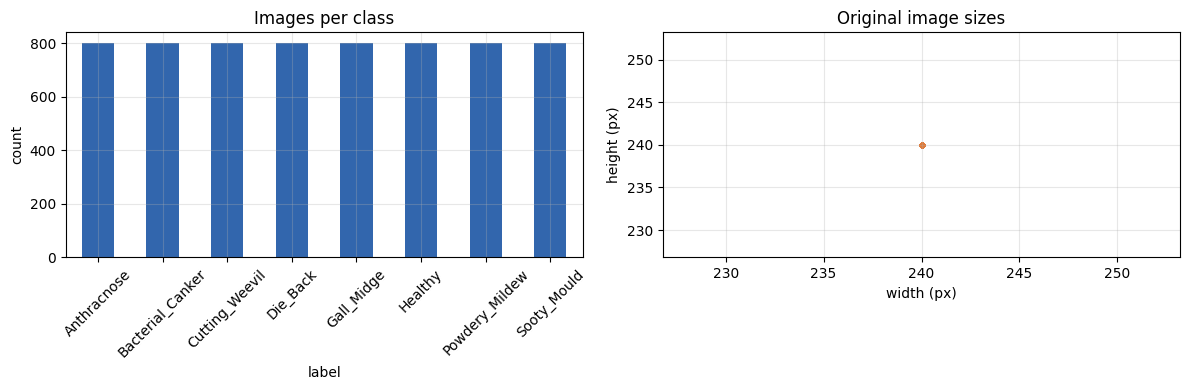

In [7]:
# --- Requirement check and summary ---
total_gb = df.bytes.sum() / 1024**3
counts = df.label.value_counts()
print("=" * 60)
print(f"Dataset                : {DATASET_NAME}")
print(f"Images                 : {len(df):,}        (requirement: >= 2,000)  ->  {'PASS' if len(df) >= 2000 else 'CHECK'}")
print(f"Size on disk (images)  : {total_gb:.2f} GB   (requirement: <= 2.5 GB) ->  {'PASS' if total_gb <= 2.5 else 'CHECK'}")
print(f"Classes                : {df.label.nunique()}  {list(counts.index)}")
print(f"Class balance          : min {counts.min()} / max {counts.max()}  (imbalance ratio {counts.max()/counts.min():.2f})")
print(f"Image width  (px)      : min {int(df.w.min())}, median {int(df.w.median())}, max {int(df.w.max())}")
print(f"Image height (px)      : min {int(df.h.min())}, median {int(df.h.median())}, max {int(df.h.max())}")
print(f"Colour modes           : {df['mode'].value_counts().to_dict()}")
print("=" * 60)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
counts.sort_index().plot.bar(ax=ax[0], color="#3266ad")
ax[0].set_title("Images per class"); ax[0].set_ylabel("count"); ax[0].tick_params(axis="x", rotation=45)
ax[1].scatter(df.w, df.h, s=8, alpha=0.4, color="#e07b39")
ax[1].set_title("Original image sizes"); ax[1].set_xlabel("width (px)"); ax[1].set_ylabel("height (px)")
plt.tight_layout(); plt.show()

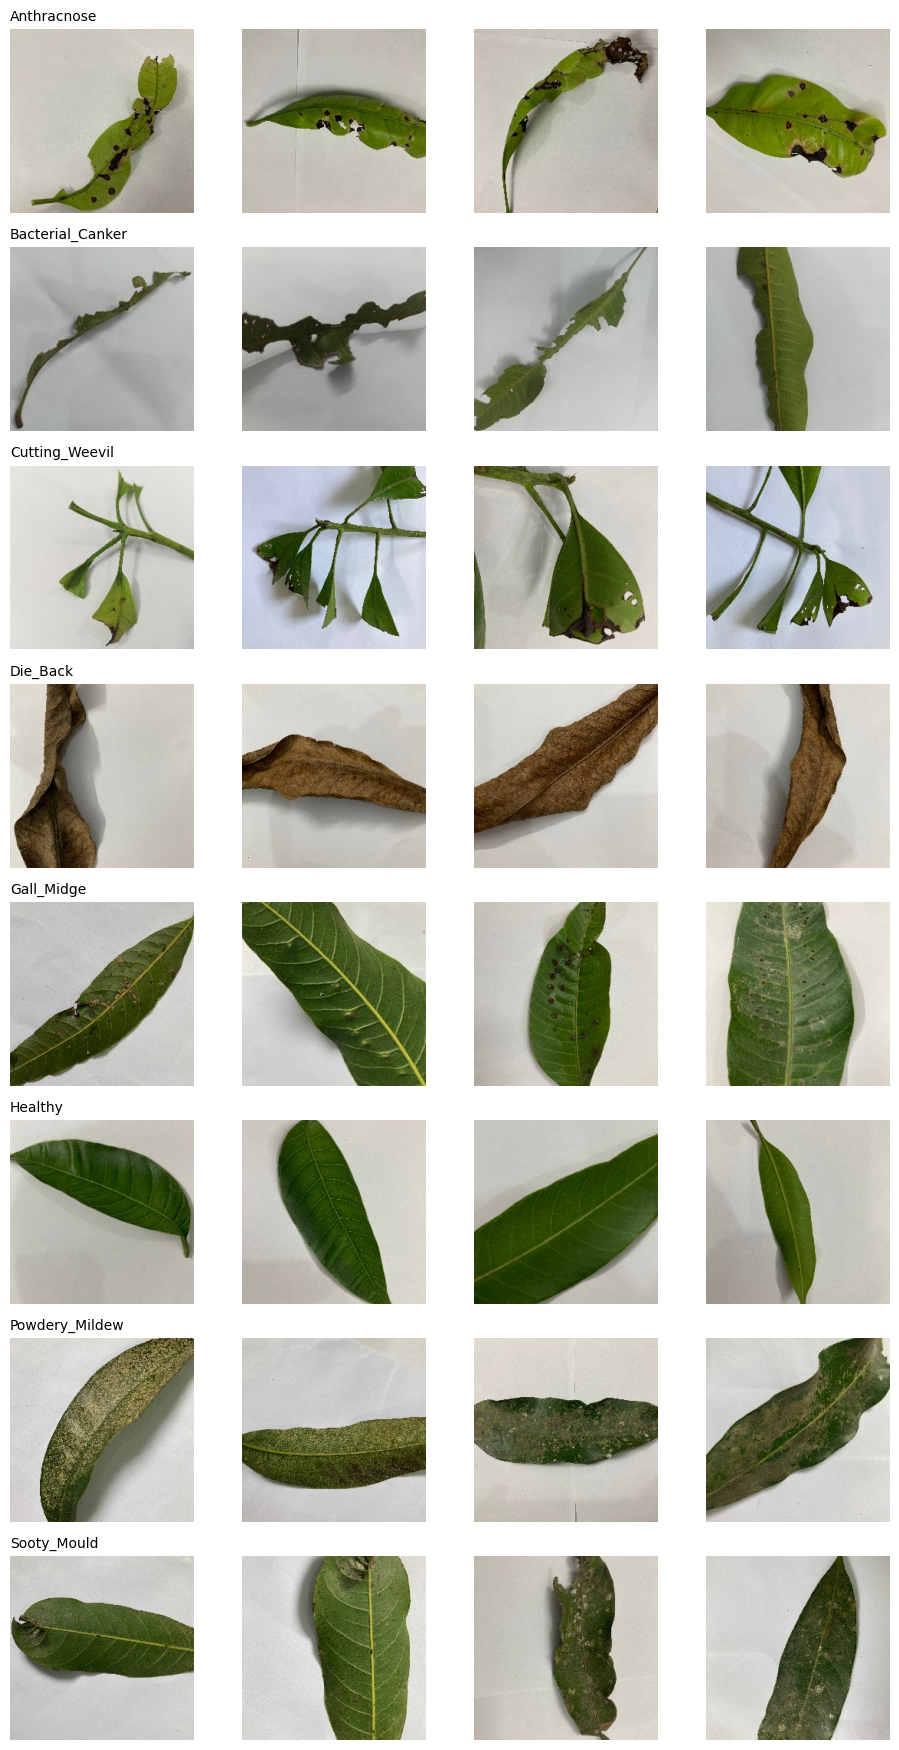

In [8]:
# --- Sample images from each class ---
classes = sorted(df.label.unique())
n_show = 4
show_classes = classes[:10]
fig, axes = plt.subplots(len(show_classes), n_show, figsize=(2.4 * n_show, 2.2 * len(show_classes)), squeeze=False)
for r, c in enumerate(show_classes):
    sample = df[df.label == c].sample(n_show, random_state=SEED, replace=len(df[df.label == c]) < n_show)
    for k, p in enumerate(sample.path):
        with Image.open(p) as im:
            axes[r][k].imshow(im.convert("RGB"))
        axes[r][k].axis("off")
        if k == 0: axes[r][k].set_title(c, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 4. Train / validation / test split

A **stratified** 70/15/15 split with a fixed seed keeps the class proportions equal in all three sets. The validation set is used to pick the best epoch. The test set is used once, at the end.

Creating a stratified random split (seed = 42).


split,train,val,test
label,,,
Anthracnose,560,120,120
Bacterial_Canker,560,120,120
Cutting_Weevil,560,120,120
Die_Back,560,120,120
Gall_Midge,560,120,120
Healthy,560,120,120
Powdery_Mildew,559,121,120
Sooty_Mould,560,120,120
TOTAL,4479,961,960


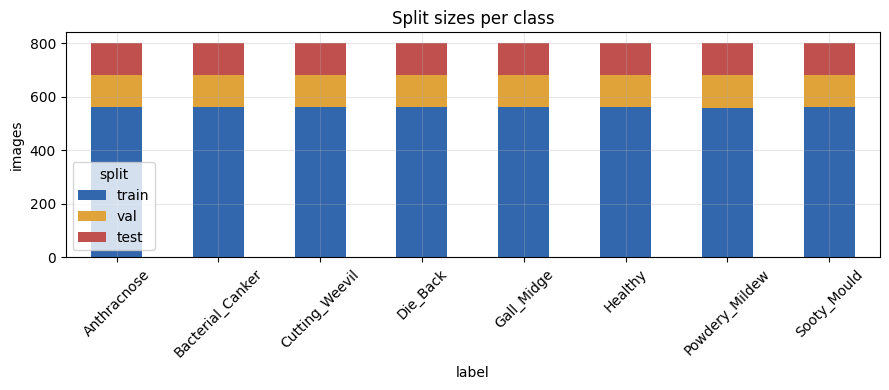

In [9]:
def make_splits(df):
    df = df.copy()
    have = set(df.split.dropna().unique()) if df.split.notna().all() else set()
    if {"train", "val", "test"} <= have:
        print("Using the dataset's own train/val/test split.")
        return df
    if have == {"train", "test"}:
        print("Dataset has train/test. Carving a validation set out of train.")
        tr = df[df.split == "train"]
        tr_idx, va_idx = train_test_split(tr.index, test_size=VAL_FRAC / (TRAIN_FRAC + VAL_FRAC),
                                          stratify=tr.label, random_state=SEED)
        df.loc[va_idx, "split"] = "val"
        return df
    print("Creating a stratified random split (seed = %d)." % SEED)
    idx = df.index
    trval_idx, te_idx = train_test_split(idx, test_size=TEST_FRAC, stratify=df.label, random_state=SEED)
    tr_idx, va_idx = train_test_split(trval_idx, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                      stratify=df.loc[trval_idx, "label"], random_state=SEED)
    df["split"] = None
    df.loc[tr_idx, "split"] = "train"; df.loc[va_idx, "split"] = "val"; df.loc[te_idx, "split"] = "test"
    return df

df = make_splits(df)
classes = sorted(df.label.unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
df["y"] = df.label.map(class_to_idx)
NUM_CLASSES = len(classes)

split_table = pd.crosstab(df.label, df.split)[["train", "val", "test"]]
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)
split_table.drop("TOTAL").plot.bar(stacked=True, figsize=(9, 4), color=["#3266ad", "#e0a339", "#c0504d"])
plt.title("Split sizes per class"); plt.ylabel("images"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

train_df = df[df.split == "train"].reset_index(drop=True)
val_df   = df[df.split == "val"].reset_index(drop=True)
test_df  = df[df.split == "test"].reset_index(drop=True)

## 5. Preprocessing

Each image is resized once to `IMG_SIZE x IMG_SIZE` and cached in memory, then normalised per channel with the **training-set** mean and std. Validation and test images get the same resize and normalisation but **no augmentation**.

In [10]:
def load_cached(frame):
    imgs = []
    for p in tqdm(frame.path, desc="caching"):
        with Image.open(p) as im:
            imgs.append(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    return imgs, frame.y.tolist()

train_imgs, train_y = load_cached(train_df)
val_imgs,   val_y   = load_cached(val_df)
test_imgs,  test_y  = load_cached(test_df)
print("In-memory cache: %.0f MB" % ((len(train_imgs) + len(val_imgs) + len(test_imgs)) * IMG_SIZE * IMG_SIZE * 3 / 1e6))

# train-set channel statistics
s = np.zeros(3); s2 = np.zeros(3); n = 0
for im in train_imgs:
    a = np.asarray(im, dtype=np.float64) / 255.0
    s += a.sum((0, 1)); s2 += (a ** 2).sum((0, 1)); n += a.shape[0] * a.shape[1]
MEAN = s / n; STD = np.sqrt(s2 / n - MEAN ** 2)
print("Train mean:", MEAN.round(4), "| std:", STD.round(4))

class ImageSet(Dataset):
    def __init__(self, imgs, targets, transform):
        self.imgs, self.targets, self.transform = imgs, targets, transform
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        return self.transform(self.imgs[i]), self.targets[i]

norm = transforms.Normalize(MEAN.tolist(), STD.tolist())

# Round 1: only convert to tensor + normalise
basic_tf = transforms.Compose([transforms.ToTensor(), norm])

# Round 2: random augmentation for TRAIN only (val/test always use basic_tf).
# NOTE: horizontal flipping preserves the label for leaf images (a flipped leaf shows the same condition).
aug_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(), norm,
])

g = torch.Generator(); g.manual_seed(SEED)
pin = device.type == "cuda"
def loader(imgs, ys, tf, shuffle):
    return DataLoader(ImageSet(imgs, ys, tf), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=pin, generator=g if shuffle else None)

train_loader_plain = loader(train_imgs, train_y, basic_tf, True)
train_loader_aug   = loader(train_imgs, train_y, aug_tf, True)
val_loader         = loader(val_imgs, val_y, basic_tf, False)
test_loader        = loader(test_imgs, test_y, basic_tf, False)
print(f"Batches per epoch: train {len(train_loader_plain)}, val {len(val_loader)}, test {len(test_loader)}")

caching:   0%|          | 0/4479 [00:00<?, ?it/s]

caching:   0%|          | 0/961 [00:00<?, ?it/s]

caching:   0%|          | 0/960 [00:00<?, ?it/s]

In-memory cache: 315 MB
Train mean: [0.6261 0.6335 0.5567] | std: [0.2378 0.2185 0.2954]
Batches per epoch: train 140, val 31, test 30


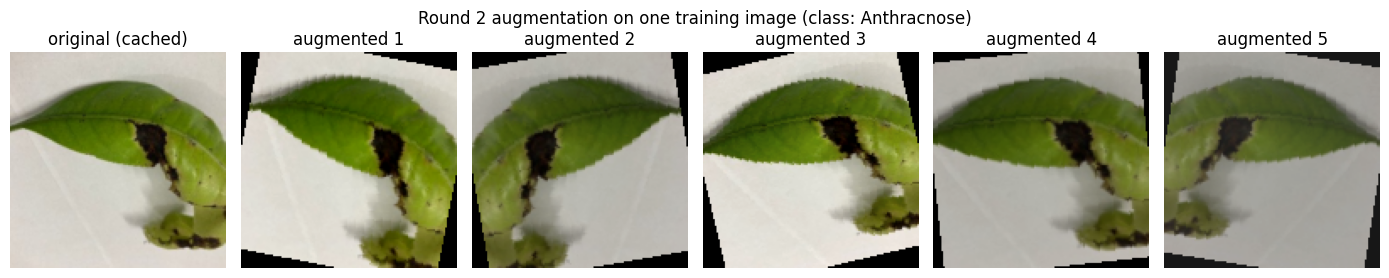

In [11]:
def denorm(t):
    # undo Normalize so a tensor can be shown with imshow
    m = torch.tensor(MEAN, dtype=torch.float32).view(3, 1, 1); s = torch.tensor(STD, dtype=torch.float32).view(3, 1, 1)
    return (t.cpu() * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

# Same training image, 5 different random augmentations
base_img = train_imgs[0]
fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
axes[0].imshow(base_img); axes[0].set_title("original (cached)")
for k in range(1, 6):
    axes[k].imshow(denorm(aug_tf(base_img))); axes[k].set_title(f"augmented {k}")
for a in axes: a.axis("off")
plt.suptitle("Round 2 augmentation on one training image (class: %s)" % classes[train_y[0]])
plt.tight_layout(); plt.show()

## 5b. Baseline: K-Nearest Neighbours

KNN [2] labels an image by majority vote among its k closest training images (L1 or L2 distance on 32 x 32 pixels). k and the distance are chosen by 5-fold cross-validation on the training set. It is a non-neural reference for the CNN.

Each image becomes a vector of 3072 numbers (32 x 32 x 3)


5-fold CV, L1:   0%|          | 0/5 [00:00<?, ?it/s]

5-fold CV, L2:   0%|          | 0/5 [00:00<?, ?it/s]

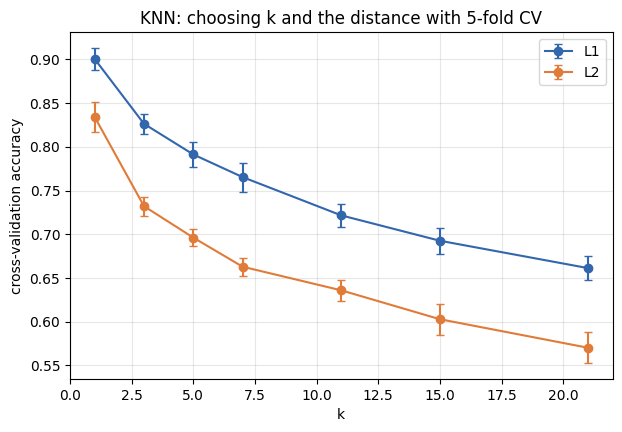

Best by cross-validation: L1, k = 1  (CV acc 0.900)
KNN test accuracy 92.3%, macro-F1 0.923  (random guessing would be 12.5%)


In [12]:
from sklearn.model_selection import StratifiedKFold

KNN_SIZE = 32
def to_vec(imgs):
    return np.stack([np.asarray(im.resize((KNN_SIZE, KNN_SIZE), Image.BILINEAR), dtype=np.float32).ravel() / 255.0 for im in imgs])

Xtr, Xva, Xte = to_vec(train_imgs), to_vec(val_imgs), to_vec(test_imgs)
ytr, yva, yte = np.array(train_y), np.array(val_y), np.array(test_y)
print("Each image becomes a vector of", Xtr.shape[1], "numbers (32 x 32 x 3)")

def knn_predict(X_train, y_train, X_query, ks, p):
    # p = 1 -> L1 distance, p = 2 -> L2 distance. Returns {k: predicted labels}.
    Xt = torch.tensor(X_train, device=device); yt = torch.tensor(y_train, device=device)
    Xq = torch.tensor(X_query, device=device)
    kmax = max(ks); out = {k: [] for k in ks}
    for i in range(0, len(Xq), 256):
        d = torch.cdist(Xq[i:i + 256], Xt, p=float(p))            # distance to every training image
        nn_idx = d.topk(kmax, largest=False).indices               # indices of the nearest ones
        lab = yt[nn_idx]                                           # their labels, nearest first
        for k in ks:
            votes = F.one_hot(lab[:, :k], NUM_CLASSES).sum(1)      # majority vote among the k nearest
            out[k].append(votes.argmax(1).cpu())
    return {k: torch.cat(v).numpy() for k, v in out.items()}

KS = [1, 3, 5, 7, 11, 15, 21]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv = {1: {k: [] for k in KS}, 2: {k: [] for k in KS}}
for p in (1, 2):
    for tr, te in tqdm(list(skf.split(Xtr, ytr)), desc=f"5-fold CV, L{p}"):
        preds = knn_predict(Xtr[tr], ytr[tr], Xtr[te], KS, p)
        for k in KS:
            cv[p][k].append((preds[k] == ytr[te]).mean())

plt.figure(figsize=(7, 4.5))
for p, col in [(1, "#3266ad"), (2, "#e07b39")]:
    m = np.array([np.mean(cv[p][k]) for k in KS]); sd = np.array([np.std(cv[p][k]) for k in KS])
    plt.errorbar(KS, m, yerr=sd, marker="o", capsize=3, label=f"L{p}", color=col)
plt.xlabel("k"); plt.ylabel("cross-validation accuracy"); plt.title("KNN: choosing k and the distance with 5-fold CV"); plt.legend(); plt.show()

best_p, best_k = max(((p, k) for p in (1, 2) for k in KS), key=lambda t: np.mean(cv[t[0]][t[1]]))
print(f"Best by cross-validation: L{best_p}, k = {best_k}  (CV acc {np.mean(cv[best_p][best_k]):.3f})")

# final KNN: train set as memory, test set scored once
knn_pred = knn_predict(Xtr, ytr, Xte, [best_k], best_p)[best_k]
knn_test_acc = accuracy_score(yte, knn_pred); knn_test_f1 = f1_score(yte, knn_pred, average="macro")
print(f"KNN test accuracy {knn_test_acc:.1%}, macro-F1 {knn_test_f1:.3f}  (random guessing would be {1 / NUM_CLASSES:.1%})")

## 6. The CNN (built from scratch)

```
Input 3 x S x S
 -> Conv(3->16) -> ReLU -> MaxPool(2)
 -> Conv(16->32) -> ReLU -> MaxPool(2)
 -> Conv(32->64) -> ReLU -> MaxPool(2)
 -> Flatten -> Dropout -> Linear(.., 128) -> ReLU -> Linear(128, 8)
```

Conv layers learn 3x3 filters, ReLU adds non-linearity, max pooling halves the size, and the linear layers give one score per class. Loss: cross-entropy (softmax inside). Optimiser: Adam.

In [13]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes, p_dropout=0.0, img_size=IMG_SIZE):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        with torch.no_grad():                                  # find the flattened size automatically
            flat = self._features(torch.zeros(1, 3, img_size, img_size)).numel()
        self.flat_dim = flat
        self.dropout = nn.Dropout(p_dropout)
        self.fc1 = nn.Linear(flat, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def _features(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        return x

    def forward(self, x):
        x = torch.flatten(self._features(x), 1)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

    @torch.no_grad()
    def feature_maps(self, x):
        # returns the activations after conv1 and conv3 (before pooling) for visualisation
        a1 = F.relu(self.conv1(x))
        x = self.pool(a1)
        x = self.pool(F.relu(self.conv2(x)))
        a3 = F.relu(self.conv3(x))
        return a1, a3

def layer_table(model):
    rows, hooks = [], []
    def hook(name):
        def f(m, i, o):
            rows.append({"layer": name, "output shape": tuple(o.shape[1:]),
                         "params": sum(p.numel() for p in m.parameters())})
        return f
    for name, m in model.named_children():
        hooks.append(m.register_forward_hook(hook(name)))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE).to(device))
    for h in hooks: h.remove()
    t = pd.DataFrame(rows)
    return t

set_seed(SEED)
_m = SimpleCNN(NUM_CLASSES).to(device)
display(layer_table(_m))
print(f"Flattened vector size: {_m.flat_dim:,}")
print(f"Total trainable parameters: {sum(p.numel() for p in _m.parameters() if p.requires_grad):,}")
del _m

,layer,output shape,params
0,conv1,"(16, 128, 128)",448
1,pool,"(16, 64, 64)",0
2,conv2,"(32, 64, 64)",4640
3,pool,"(32, 32, 32)",0
4,conv3,"(64, 32, 32)",18496
5,pool,"(64, 16, 16)",0
6,dropout,"(16384,)",0
7,fc1,"(128,)",2097280
8,fc2,"(8,)",1032


Flattened vector size: 16,384
Total trainable parameters: 2,121,896


## 7. Training

After every epoch the model is evaluated on the validation set, and the weights of the epoch with the highest validation accuracy are kept.

In [14]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item(); total += y.size(0)
    return loss_sum / total, correct / total

def train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LR, name="model", opt="adam", verbose=True):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr) if opt == "adam" else torch.optim.SGD(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}
    best_acc, best_state, best_ep = -1, None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc"], [tl, vl, ta, va]):
            hist[k].append(v)
        flag = ""
        if va > best_acc:
            best_acc, best_ep, best_state = va, ep, copy.deepcopy(model.state_dict()); flag = "  <- best"
        if verbose: print(f"[{name}] epoch {ep:2d}/{epochs}  train_loss={tl:.3f} train_acc={ta:.3f} | val_loss={vl:.3f} val_acc={va:.3f}{flag}")
    hist["best_epoch"] = best_ep
    hist["seconds"] = time.time() - t0
    model.load_state_dict(best_state)           # go back to the best epoch
    print(f"[{name}] finished in {hist['seconds']:.0f}s, best epoch {best_ep}, best val acc {best_acc:.3f}")
    return hist

### Round 1: no augmentation, no dropout (baseline)

In [15]:
set_seed(SEED)
model_plain = SimpleCNN(NUM_CLASSES, p_dropout=0.0).to(device)
hist_plain = train_model(model_plain, train_loader_plain, val_loader, name="Round 1")

[Round 1] epoch  1/25  train_loss=0.935 train_acc=0.638 | val_loss=0.445 val_acc=0.848  <- best
[Round 1] epoch  2/25  train_loss=0.365 train_acc=0.869 | val_loss=0.313 val_acc=0.902  <- best
[Round 1] epoch  3/25  train_loss=0.203 train_acc=0.931 | val_loss=0.300 val_acc=0.889
[Round 1] epoch  4/25  train_loss=0.179 train_acc=0.936 | val_loss=0.158 val_acc=0.948  <- best
[Round 1] epoch  5/25  train_loss=0.079 train_acc=0.974 | val_loss=0.127 val_acc=0.956  <- best
[Round 1] epoch  6/25  train_loss=0.071 train_acc=0.974 | val_loss=0.164 val_acc=0.944
[Round 1] epoch  7/25  train_loss=0.058 train_acc=0.981 | val_loss=0.128 val_acc=0.966  <- best
[Round 1] epoch  8/25  train_loss=0.015 train_acc=0.995 | val_loss=0.097 val_acc=0.978  <- best
[Round 1] epoch  9/25  train_loss=0.018 train_acc=0.995 | val_loss=0.149 val_acc=0.958
[Round 1] epoch 10/25  train_loss=0.140 train_acc=0.956 | val_loss=0.241 val_acc=0.929
[Round 1] epoch 11/25  train_loss=0.038 train_acc=0.990 | val_loss=0.142 val

### Round 2: augmentation + dropout (0.5)

Same architecture, optimiser, epochs and seed. Only two things change, so any difference is caused by them.

In [16]:
set_seed(SEED)
model_aug = SimpleCNN(NUM_CLASSES, p_dropout=0.5).to(device)
hist_aug = train_model(model_aug, train_loader_aug, val_loader, name="Round 2")

[Round 2] epoch  1/25  train_loss=1.505 train_acc=0.420 | val_loss=0.802 val_acc=0.694  <- best
[Round 2] epoch  2/25  train_loss=0.838 train_acc=0.680 | val_loss=0.610 val_acc=0.763  <- best
[Round 2] epoch  3/25  train_loss=0.597 train_acc=0.771 | val_loss=0.464 val_acc=0.826  <- best
[Round 2] epoch  4/25  train_loss=0.502 train_acc=0.818 | val_loss=0.381 val_acc=0.878  <- best
[Round 2] epoch  5/25  train_loss=0.428 train_acc=0.841 | val_loss=0.347 val_acc=0.875
[Round 2] epoch  6/25  train_loss=0.402 train_acc=0.848 | val_loss=0.329 val_acc=0.875
[Round 2] epoch  7/25  train_loss=0.374 train_acc=0.859 | val_loss=0.290 val_acc=0.901  <- best
[Round 2] epoch  8/25  train_loss=0.330 train_acc=0.879 | val_loss=0.244 val_acc=0.930  <- best
[Round 2] epoch  9/25  train_loss=0.298 train_acc=0.891 | val_loss=0.185 val_acc=0.940  <- best
[Round 2] epoch 10/25  train_loss=0.273 train_acc=0.902 | val_loss=0.151 val_acc=0.963  <- best
[Round 2] epoch 11/25  train_loss=0.251 train_acc=0.910 | 

### Learning-rate experiment

The same CNN (same seed and data, plain SGD, no dropout, 10 epochs) is trained with four learning rates to show how the step size affects convergence.

[SGD lr=0.001] finished in 23s, best epoch 10, best val acc 0.377
[SGD lr=0.01] finished in 23s, best epoch 10, best val acc 0.907
[SGD lr=0.1] finished in 24s, best epoch 9, best val acc 0.760
[SGD lr=1.0] finished in 24s, best epoch 1, best val acc 0.125


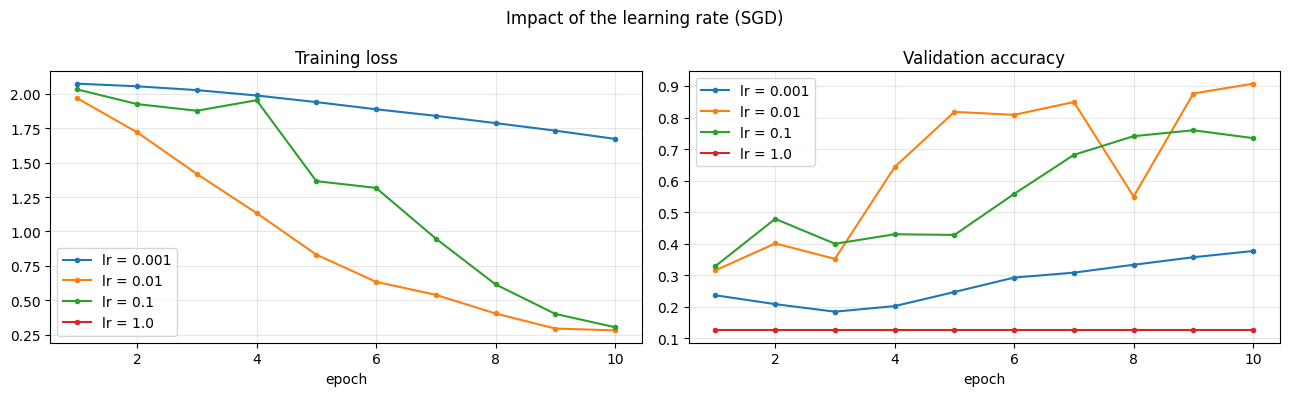

,final train loss,best val acc
lr = 0.001,1.672,0.377
lr = 0.01,0.281,0.907
lr = 0.1,0.305,0.760
lr = 1.0,nan,0.125


In [17]:
LR_LIST = [0.001, 0.01, 0.1, 1.0]
LR_EPOCHS = 10
lr_hist = {}
for lr in LR_LIST:
    set_seed(SEED)
    m_lr = SimpleCNN(NUM_CLASSES).to(device)
    lr_hist[lr] = train_model(m_lr, train_loader_plain, val_loader, epochs=LR_EPOCHS, lr=lr, name=f"SGD lr={lr}", opt="sgd", verbose=False)
    del m_lr

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for lr in LR_LIST:
    ax[0].plot(range(1, LR_EPOCHS + 1), lr_hist[lr]["train_loss"], "o-", ms=3, label=f"lr = {lr}")
    ax[1].plot(range(1, LR_EPOCHS + 1), lr_hist[lr]["val_acc"], "o-", ms=3, label=f"lr = {lr}")
ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.suptitle("Impact of the learning rate (SGD)"); plt.tight_layout(); plt.show()

lr_table = pd.DataFrame({f"lr = {lr}": {"final train loss": lr_hist[lr]["train_loss"][-1],
                                         "best val acc": max(lr_hist[lr]["val_acc"])} for lr in LR_LIST}).T
display(lr_table.style.format("{:.3f}"))

## 8. Result analysis

### 8.1 Loss and accuracy curves

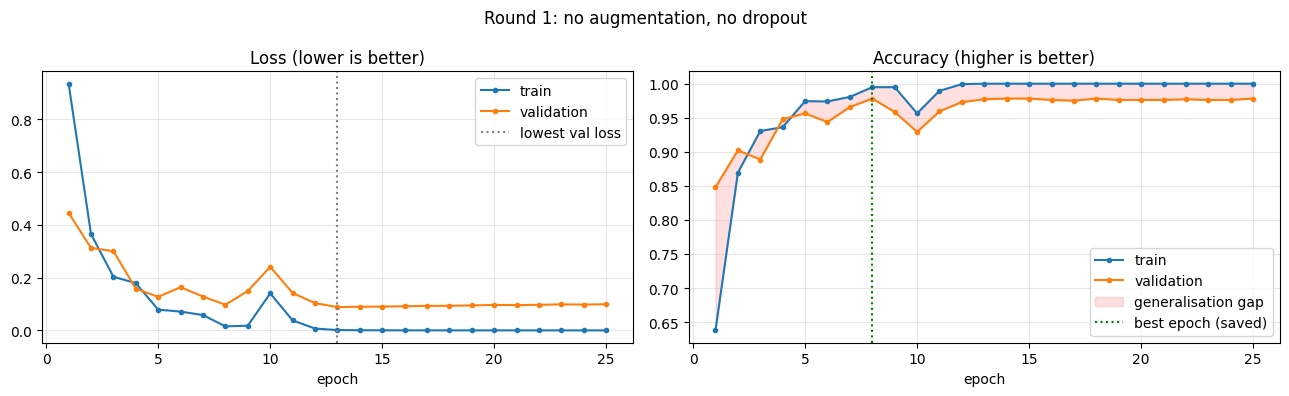

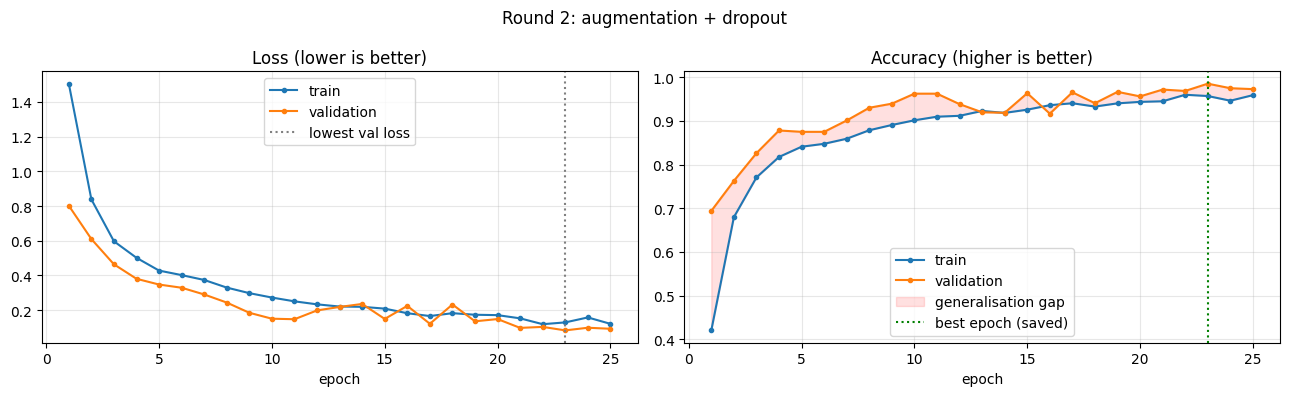

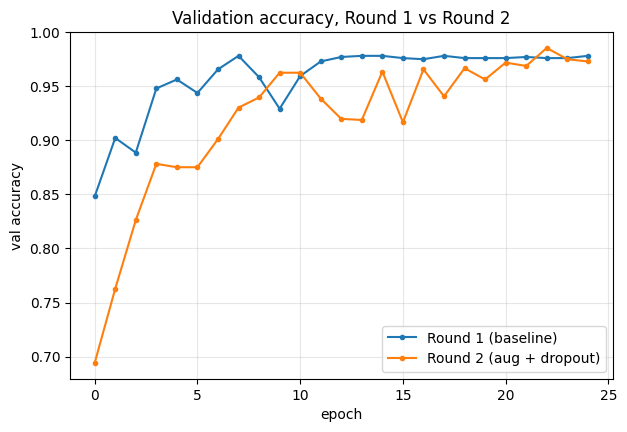

In [18]:
def plot_history(h, title):
    ep = np.arange(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(ep, h["train_loss"], "o-", ms=3, label="train"); ax[0].plot(ep, h["val_loss"], "o-", ms=3, label="validation")
    ax[0].axvline(int(np.argmin(h["val_loss"])) + 1, ls=":", color="gray", label="lowest val loss")
    ax[0].set_title("Loss (lower is better)"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], "o-", ms=3, label="train"); ax[1].plot(ep, h["val_acc"], "o-", ms=3, label="validation")
    ax[1].fill_between(ep, h["val_acc"], h["train_acc"], alpha=0.12, color="red", label="generalisation gap")
    ax[1].axvline(h["best_epoch"], ls=":", color="green", label="best epoch (saved)")
    ax[1].set_title("Accuracy (higher is better)"); ax[1].set_xlabel("epoch"); ax[1].legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_history(hist_plain, "Round 1: no augmentation, no dropout")
plot_history(hist_aug,   "Round 2: augmentation + dropout")

plt.figure(figsize=(7, 4.5))
plt.plot(hist_plain["val_acc"], "o-", ms=3, label="Round 1 (baseline)")
plt.plot(hist_aug["val_acc"],   "o-", ms=3, label="Round 2 (aug + dropout)")
plt.title("Validation accuracy, Round 1 vs Round 2"); plt.xlabel("epoch"); plt.ylabel("val accuracy"); plt.legend(); plt.show()

### 8.2 Final evaluation on the held-out test set

Both models are loaded at their best validation epoch and scored once on the test set.

In [19]:
@torch.no_grad()
def predict(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        P.append(F.softmax(model(x.to(device)), 1).cpu()); Y.append(y)
    P = torch.cat(P).numpy(); Y = torch.cat(Y).numpy()
    return Y, P.argmax(1), P

res = {}
for name, m, h in [("Round 1 (baseline)", model_plain, hist_plain), ("Round 2 (aug + dropout)", model_aug, hist_aug)]:
    y_true, y_pred, probs = predict(m, test_loader)
    be = h["best_epoch"] - 1
    res[name] = dict(model=m, hist=h, y_true=y_true, y_pred=y_pred, probs=probs,
                     test_acc=accuracy_score(y_true, y_pred),
                     test_f1=f1_score(y_true, y_pred, average="macro"))

summary = pd.DataFrame([{
    "model": n,
    "best epoch": r["hist"]["best_epoch"],
    "train acc (best ep)": r["hist"]["train_acc"][r["hist"]["best_epoch"] - 1],
    "val acc (best ep)": r["hist"]["val_acc"][r["hist"]["best_epoch"] - 1],
    "test acc": r["test_acc"],
    "test macro-F1": r["test_f1"],
    "train-val gap (final ep)": r["hist"]["train_acc"][-1] - r["hist"]["val_acc"][-1],
    "val loss (final ep)": r["hist"]["val_loss"][-1],
    "train time (s)": r["hist"]["seconds"],
} for n, r in res.items()]).set_index("model")
summary.loc[f"KNN pixels (L{best_p}, k={best_k})", ["test acc", "test macro-F1"]] = [knn_test_acc, knn_test_f1]
display(summary.style.format("{:.3f}", na_rep="-"))

FINAL = max(res, key=lambda n: res[n]["hist"]["val_acc"][res[n]["hist"]["best_epoch"] - 1])   # chosen on VALIDATION, not test
print("Final model (highest validation accuracy):", FINAL)

,best epoch,train acc (best ep),val acc (best ep),test acc,test macro-F1,train-val gap (final ep),val loss (final ep),train time (s)
model,,,,,,,,
Round 1 (baseline),8.000,0.995,0.978,0.961,0.961,0.022,0.099,58.315
Round 2 (aug + dropout),23.000,0.957,0.985,0.978,0.978,-0.014,0.093,132.032
"KNN pixels (L1, k=1)",-,-,-,0.923,0.923,-,-,-


Final model (highest validation accuracy): Round 2 (aug + dropout)


### 8.3 Confusion matrix and per-class metrics

- **Precision** of a class: of the images predicted as this class, how many really are.
- **Recall** of a class: of the images that really are this class, how many were found.
- **F1**: the harmonic mean of precision and recall.

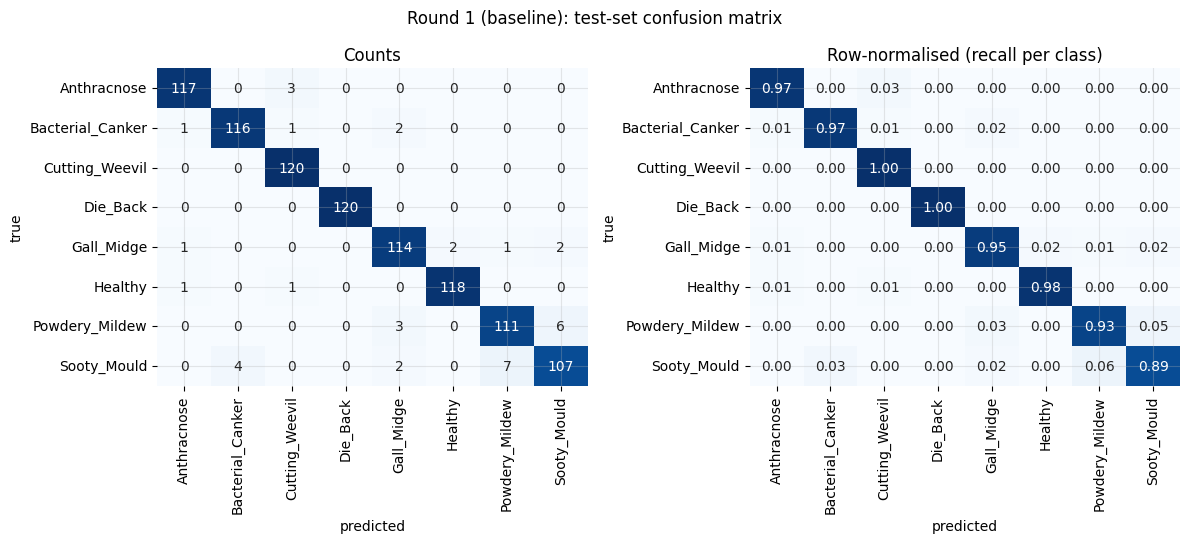


Round 1 (baseline)


,precision,recall,f1-score,support
Anthracnose,0.975,0.975,0.975,120
Bacterial_Canker,0.967,0.967,0.967,120
Cutting_Weevil,0.960,1.000,0.980,120
Die_Back,1.000,1.000,1.000,120
Gall_Midge,0.942,0.950,0.946,120
Healthy,0.983,0.983,0.983,120
Powdery_Mildew,0.933,0.925,0.929,120
Sooty_Mould,0.930,0.892,0.911,120
accuracy,0.961,0.961,0.961,1
macro avg,0.961,0.961,0.961,960


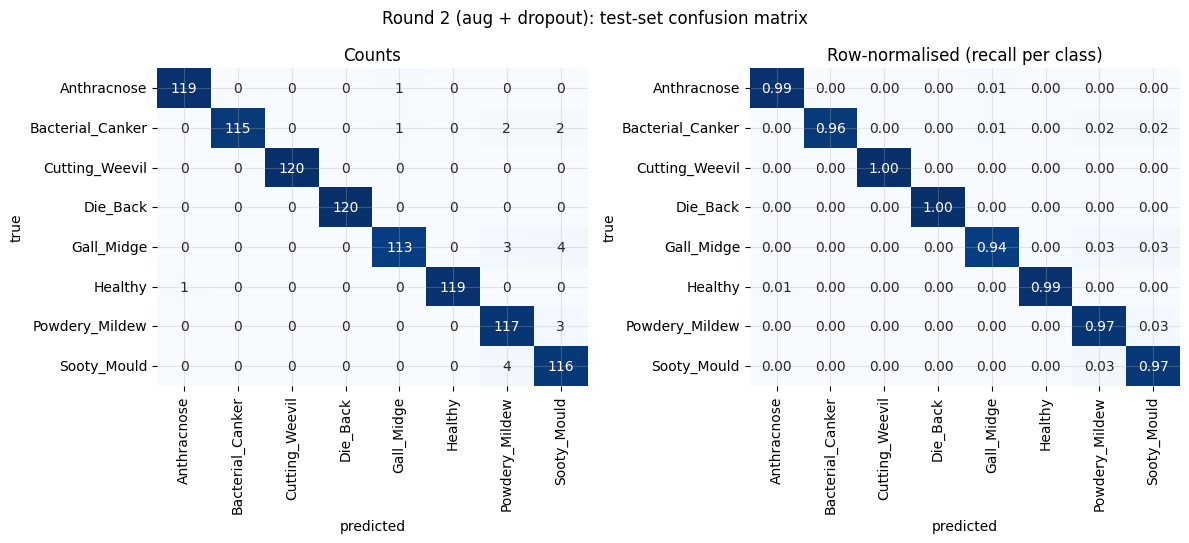


Round 2 (aug + dropout)


,precision,recall,f1-score,support
Anthracnose,0.992,0.992,0.992,120
Bacterial_Canker,1.000,0.958,0.979,120
Cutting_Weevil,1.000,1.000,1.000,120
Die_Back,1.000,1.000,1.000,120
Gall_Midge,0.983,0.942,0.962,120
Healthy,1.000,0.992,0.996,120
Powdery_Mildew,0.929,0.975,0.951,120
Sooty_Mould,0.928,0.967,0.947,120
accuracy,0.978,0.978,0.978,1
macro avg,0.979,0.978,0.978,960


In [20]:
def show_confusion(r, title):
    cm = confusion_matrix(r["y_true"], r["y_pred"], labels=range(NUM_CLASSES))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    sz = max(5, 0.55 * NUM_CLASSES)
    fig, ax = plt.subplots(1, 2, figsize=(2 * sz + 2, sz + 0.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[0], cbar=False)
    ax[0].set_title("Counts"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[1], cbar=False, vmin=0, vmax=1)
    ax[1].set_title("Row-normalised (recall per class)"); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true")
    fig.suptitle(title); plt.tight_layout(); plt.show()
    return cm

for n, r in res.items():
    r["cm"] = show_confusion(r, f"{n}: test-set confusion matrix")
    rep = pd.DataFrame(classification_report(r["y_true"], r["y_pred"], target_names=classes, output_dict=True, zero_division=0)).T
    r["report"] = rep
    print(f"\n{n}")
    display(rep.style.format("{:.3f}", subset=["precision", "recall", "f1-score"]).format("{:.0f}", subset=["support"]))

### 8.4 What did the final model get wrong?

Misclassified test images, sorted so the **most confident mistakes come first**. These are the most informative errors: the model was sure and still wrong.

Round 2 (aug + dropout): 21 wrong out of 960 test images (2.2%)


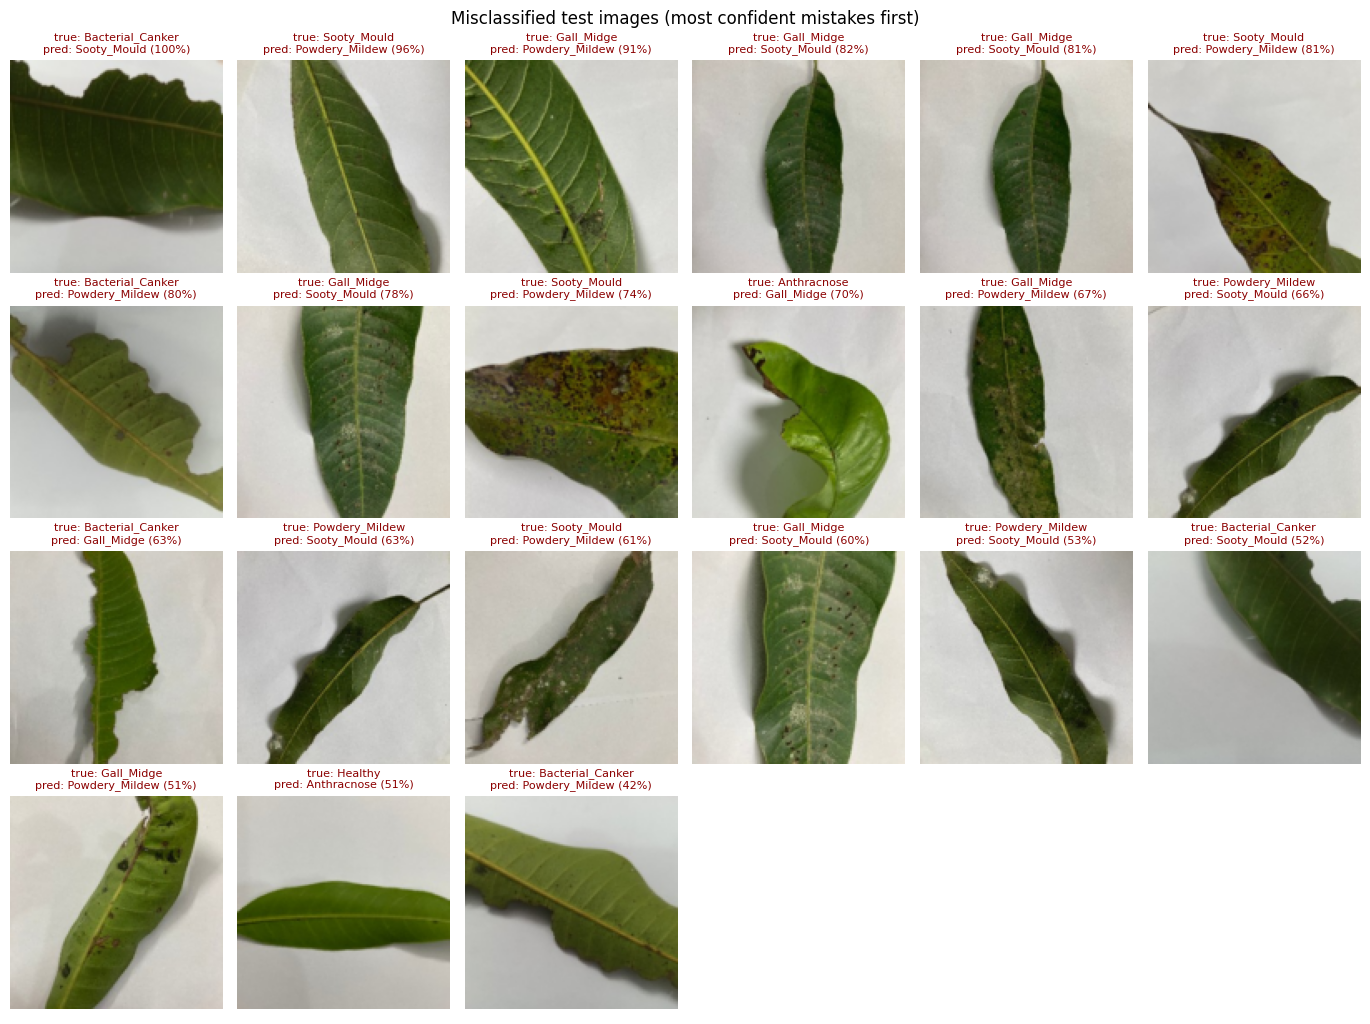

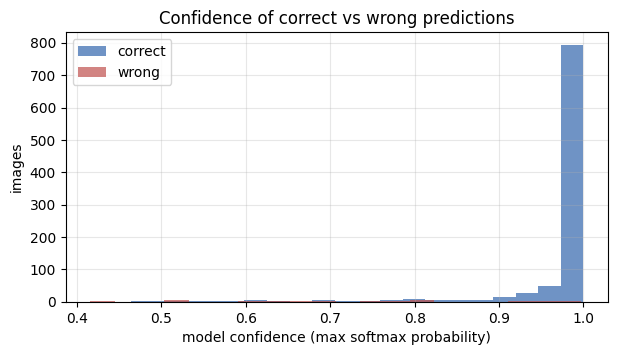

In [21]:
r = res[FINAL]
wrong = np.where(r["y_true"] != r["y_pred"])[0]
conf = r["probs"].max(1)
wrong = wrong[np.argsort(-conf[wrong])]
print(f"{FINAL}: {len(wrong)} wrong out of {len(r['y_true'])} test images ({len(wrong)/len(r['y_true']):.1%})")

k = min(24, len(wrong))
if k:
    cols = 6; rows = int(np.ceil(k / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.3, rows * 2.6), squeeze=False)
    for a in axes.ravel(): a.axis("off")
    for j, i in enumerate(wrong[:k]):
        a = axes.ravel()[j]
        a.imshow(test_imgs[i])
        a.set_title(f"true: {classes[r['y_true'][i]]}\npred: {classes[r['y_pred'][i]]} ({conf[i]:.0%})", fontsize=8, color="darkred")
    plt.suptitle("Misclassified test images (most confident mistakes first)"); plt.tight_layout(); plt.show()

# how sure is the model when it is right vs wrong?
ok = r["y_true"] == r["y_pred"]
plt.figure(figsize=(7, 3.5))
plt.hist(conf[ok], bins=20, alpha=0.7, label="correct", color="#3266ad"); plt.hist(conf[~ok], bins=20, alpha=0.7, label="wrong", color="#c0504d")
plt.xlabel("model confidence (max softmax probability)"); plt.ylabel("images"); plt.legend(); plt.title("Confidence of correct vs wrong predictions"); plt.show()

### 8.5 Filters and feature maps

The first-layer filters are small colour and edge detectors. Feature maps show where a layer responds to a pattern in a real image.

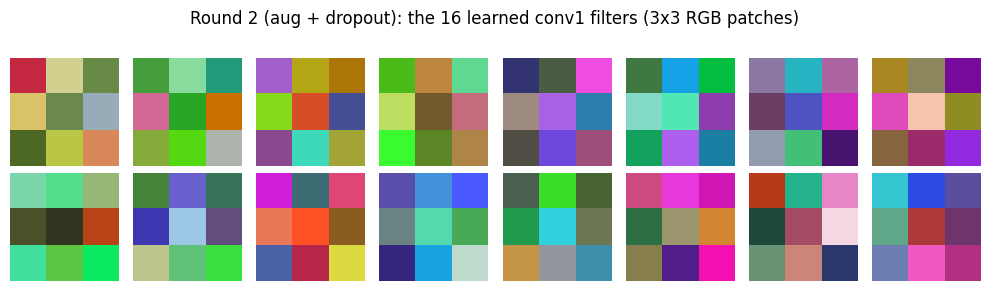

conv1 output: (16, 128, 128) | conv3 output: (64, 32, 32)


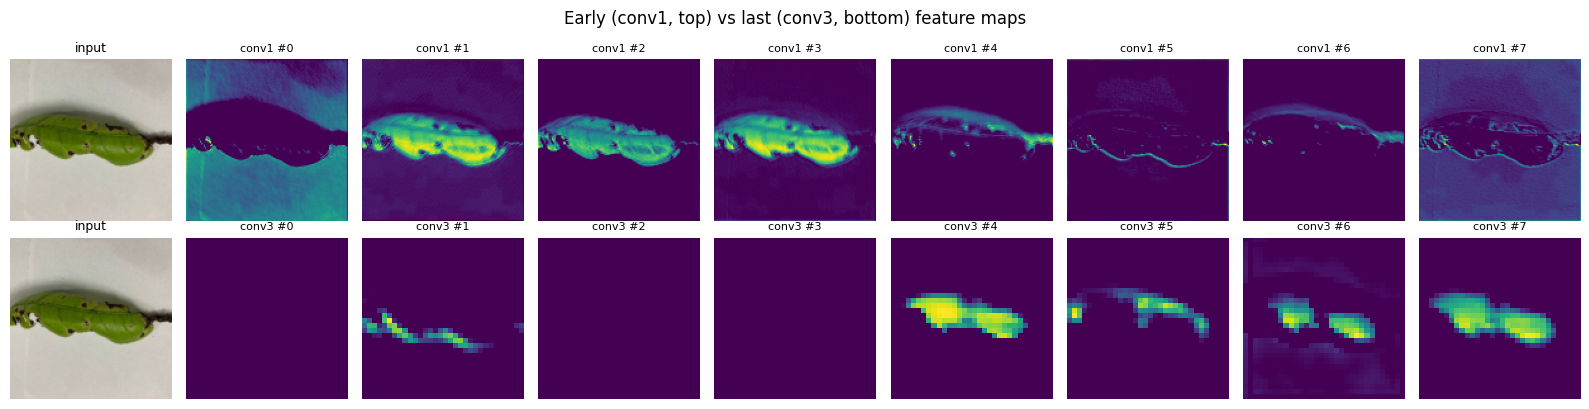

In [22]:
m = res[FINAL]["model"].eval()

# (1) the 16 learned conv1 filters
w = m.conv1.weight.detach().cpu().clone()
w = (w - w.min()) / (w.max() - w.min() + 1e-8)
fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for i, a in enumerate(axes.ravel()):
    a.imshow(w[i].permute(1, 2, 0)); a.axis("off")
plt.suptitle(f"{FINAL}: the 16 learned conv1 filters (3x3 RGB patches)"); plt.tight_layout(); plt.show()

# (2) feature maps for one correctly classified test image
ok_idx = np.where(res[FINAL]["y_true"] == res[FINAL]["y_pred"])[0]
i0 = int(ok_idx[0]) if len(ok_idx) else 0
x = basic_tf(test_imgs[i0]).unsqueeze(0).to(device)
a1, a3 = m.feature_maps(x); a1, a3 = a1.cpu()[0], a3.cpu()[0]
print("conv1 output:", tuple(a1.shape), "| conv3 output:", tuple(a3.shape))

fig, axes = plt.subplots(2, 9, figsize=(16, 4.2))
axes[0][0].imshow(test_imgs[i0]); axes[0][0].set_title("input", fontsize=9)
for j in range(8):
    axes[0][j + 1].imshow(a1[j], cmap="viridis"); axes[0][j + 1].set_title(f"conv1 #{j}", fontsize=8)
axes[1][0].imshow(test_imgs[i0]); axes[1][0].set_title("input", fontsize=9)
for j in range(8):
    axes[1][j + 1].imshow(a3[j], cmap="viridis"); axes[1][j + 1].set_title(f"conv3 #{j}", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.suptitle("Early (conv1, top) vs last (conv3, bottom) feature maps"); plt.tight_layout(); plt.show()

## 9. Discussion and conclusion

Generated from the measured results of this run.

In [28]:
from IPython.display import Markdown, display

r1, r2 = res["Round 1 (baseline)"], res["Round 2 (aug + dropout)"]
fin = res[FINAL]
cm_f = fin["cm"]; rec_f = np.diag(cm_f) / cm_f.sum(1).clip(min=1)
n_params = sum(p.numel() for p in fin["model"].parameters())
cnt = df.label.value_counts()
gap = lambda h: h["train_acc"][-1] - h["val_acc"][-1]
def gap_word(g):
    return "pronounced overfitting" if g > 0.15 else ("moderate overfitting" if g > 0.05 else "little overfitting")

P = []
# 1. dataset
P.append(f"**1. Dataset.** The dataset contains {len(df):,} images in {NUM_CLASSES} classes ({cnt.min()} to {cnt.max()} images per class, so it is {'balanced' if cnt.max() / cnt.min() < 1.2 else 'imbalanced'}), "
         f"with a total size of {total_gb:.2f} GB ({'which satisfies' if (len(df) >= 2000 and total_gb <= 2.5) else 'which does not satisfy'} the requirement of at least 2,000 images and at most 2.5 GB). "
         f"The images are {int(df.w.median())} x {int(df.h.median())} px. They were split with stratification into "
         f"{len(train_df):,} training, {len(val_df):,} validation and {len(test_df):,} test images. "
         f"Because the classes are balanced, overall accuracy is a meaningful measure, and macro-F1 is reported alongside it. "
         f"Limitations: all photos come from one region and one capture setup, and several photos may show the same leaf, so the test score may be somewhat optimistic for images from other sources.")

# 2. model
P.append(f"**2. Model.** The CNN has three convolution blocks (16, 32 and 64 filters of size 3 x 3, each followed by ReLU and 2 x 2 max pooling) and a classification head "
         f"(flatten, dropout, a 128-unit fully connected layer with ReLU, and a {NUM_CLASSES}-way output layer). It has {n_params:,} trainable parameters and is trained with the cross-entropy loss and the Adam optimiser [4].")

# 3. KNN vs CNN
best_cnn_acc = max(r1["test_acc"], r2["test_acc"])
cmp = ("clearly outperforms" if best_cnn_acc - knn_test_acc > 0.05 else ("is comparable to" if abs(best_cnn_acc - knn_test_acc) <= 0.05 else "is below"))
P.append(f"**3. KNN baseline versus CNN.** Cross-validation selected the L{best_p} distance with k = {best_k} (mean CV accuracy {np.mean(cv[best_p][best_k]):.1%}). "
         f"On the test set KNN reaches {knn_test_acc:.1%} accuracy (macro-F1 {knn_test_f1:.3f}) against a chance level of {1 / NUM_CLASSES:.1%}. "
         f"The best CNN reaches {best_cnn_acc:.1%}, so the CNN {cmp} the pixel-distance baseline ({best_cnn_acc - knn_test_acc:+.1%} points). "
         f"Pixel distances ignore spatial structure, whereas convolution filters learn local patterns such as spots and textures.")

# 4. Round 1
h = r1["hist"]; e_min = int(np.argmin(h["val_loss"])) + 1
rose = h["val_loss"][-1] > 1.1 * min(h["val_loss"])
ow = gap_word(gap(h)) if gap(h) > 0.05 else ("mild overfitting" if rose else "little overfitting")
P.append(f"**4. Round 1 (no augmentation, no dropout).** Final-epoch training accuracy is {h['train_acc'][-1]:.1%} versus {h['val_acc'][-1]:.1%} on validation, a gap of {gap(h):+.1%} points, which indicates {ow}. "
         f"Validation loss is lowest at epoch {e_min} of {len(h['val_loss'])}" + (f" and then rises to {h['val_loss'][-1]:.3f} while the training loss falls to {h['train_loss'][-1]:.3f}, a typical sign that the network starts to memorise the training images. " if rose else ". ")
         + f"The checkpoint with the best validation accuracy (epoch {h['best_epoch']}) reaches {r1['test_acc']:.1%} on the test set.")

# 5. Round 2
h2 = r2["hist"]; d = r2["test_acc"] - r1["test_acc"]; dg = gap(h) - gap(h2)
verdict = ("improved" if d > 0.01 else ("reduced" if d < -0.01 else "did not meaningfully change"))
P.append(f"**5. Round 2 (augmentation and dropout).** The final train-validation gap is {gap(h2):+.1%} points compared with {gap(h):+.1%} in Round 1 (a change of {dg:+.1%} points). "
         f"Test accuracy {verdict} from {r1['test_acc']:.1%} to {r2['test_acc']:.1%} (macro-F1 {r1['test_f1']:.3f} to {r2['test_f1']:.3f}). "
         + ("Regularisation therefore reduced overfitting and helped generalisation. " if (dg > 0.02 and d >= -0.01) else
            "The regularisation effect is small in this run. ")
         + "Since each configuration was trained once with a single seed, differences of one or two points should be treated as indicative rather than conclusive.")

# 6. LR
diverged = [lr for lr in LR_LIST if np.isnan(lr_hist[lr]["train_loss"][-1]) or lr_hist[lr]["train_loss"][-1] > 3 * np.log(NUM_CLASSES)]
stuck = [lr for lr in LR_LIST if lr not in diverged and max(lr_hist[lr]["val_acc"]) < 1.5 / NUM_CLASSES]
ok = [lr for lr in LR_LIST if lr not in diverged and lr not in stuck]
best_lr = max(ok, key=lambda lr: max(lr_hist[lr]["val_acc"])) if ok else None
txt = "**6. Learning rate.** "
if best_lr is not None:
    txt += f"With plain SGD the best validation accuracy ({max(lr_hist[best_lr]['val_acc']):.1%}) was obtained with a learning rate of {best_lr}. "
    slow = [lr for lr in ok if lr < best_lr and max(lr_hist[lr]['val_acc']) < max(lr_hist[best_lr]['val_acc']) - 0.03]
    if slow:
        txt += "Smaller values (" + ", ".join(str(x) for x in slow) + f") learned more slowly and had not caught up after {LR_EPOCHS} epochs. "
    big = [lr for lr in ok if lr > best_lr and max(lr_hist[lr]['val_acc']) < max(lr_hist[best_lr]['val_acc']) - 0.03]
    if big:
        txt += "Larger values (" + ", ".join(str(x) for x in big) + ") trained less stably and ended with lower validation accuracy. "
if stuck:
    txt += "Learning rate(s) " + ", ".join(str(x) for x in stuck) + f" made almost no progress within {LR_EPOCHS} epochs (validation accuracy stayed near chance), which indicates a step size that is too small for this training budget. "
if diverged:
    txt += "Learning rate(s) " + ", ".join(str(x) for x in diverged) + " diverged (the loss became NaN or grew very large), which shows that too large a step overshoots the minimum. "
txt += "A good learning rate balances convergence speed and stability. "
P.append(txt)

# 7. per class
off = cm_f.copy(); np.fill_diagonal(off, 0); a_, b_ = np.unravel_index(off.argmax(), off.shape)
P.append(f"**7. Per-class results ({FINAL}).** Recall ranges from {rec_f.min():.1%} for '{classes[int(rec_f.argmin())]}' to {rec_f.max():.1%} for '{classes[int(rec_f.argmax())]}'. "
         + (f"The most frequent confusion is '{classes[a_]}' predicted as '{classes[b_]}' ({off[a_, b_]} test images). " if off.max() > 0 else "")
         + "The misclassified-image grid lets these errors be inspected visually; confusions between conditions with similar lesion colour or texture are expected for a small network trained on downscaled images.")

# 8. filters
P.append("**8. Learned features.** The first-layer filters are small 3 x 3 colour patches that typically respond to colour and edge patterns. Feature maps of the first layer remain close to the input image, while those of the last layer are small and abstract and indicate where higher-level patterns occur (see Section 8.5).")

# conclusion (consistent with points 4 and 5)
P.append(f"### Conclusion\n\nA small CNN trained from scratch classifies the {NUM_CLASSES} mango leaf conditions with {fin['test_acc']:.1%} test accuracy and {fin['test_f1']:.3f} macro-F1 ({FINAL}), compared with {knn_test_acc:.1%} for the pixel-KNN baseline. "
         f"Without regularisation the training loss fell to {h['train_loss'][-1]:.3f} while the validation loss stopped improving (lowest {min(h['val_loss']):.3f} at epoch {e_min}, {h['val_loss'][-1]:.3f} at the end), which indicates {ow}. "
         f"Augmentation with dropout changed the test accuracy by {d:+.1%} points, which is a small difference from a single run. "
         "Natural next steps are transfer learning from a pretrained network, images from additional farms and cameras, repeated runs with different seeds, and cross-validation of the CNN.")

display(Markdown("\n\n".join(P)))

**1. Dataset.** The dataset contains 6,400 images in 8 classes (800 to 800 images per class, so it is balanced), with a total size of 0.13 GB (which satisfies the requirement of at least 2,000 images and at most 2.5 GB). The images are 240 x 240 px. They were split with stratification into 4,479 training, 961 validation and 960 test images. Because the classes are balanced, overall accuracy is a meaningful measure, and macro-F1 is reported alongside it. Limitations: all photos come from one region and one capture setup, and several photos may show the same leaf, so the test score may be somewhat optimistic for images from other sources.

**2. Model.** The CNN has three convolution blocks (16, 32 and 64 filters of size 3 x 3, each followed by ReLU and 2 x 2 max pooling) and a classification head (flatten, dropout, a 128-unit fully connected layer with ReLU, and a 8-way output layer). It has 2,121,896 trainable parameters and is trained with the cross-entropy loss and the Adam optimiser [4].

**3. KNN baseline versus CNN.** Cross-validation selected the L1 distance with k = 1 (mean CV accuracy 90.0%). On the test set KNN reaches 92.3% accuracy (macro-F1 0.923) against a chance level of 12.5%. The best CNN reaches 97.8%, so the CNN clearly outperforms the pixel-distance baseline (+5.5% points). Pixel distances ignore spatial structure, whereas convolution filters learn local patterns such as spots and textures.

**4. Round 1 (no augmentation, no dropout).** Final-epoch training accuracy is 100.0% versus 97.8% on validation, a gap of +2.2% points, which indicates mild overfitting. Validation loss is lowest at epoch 13 of 25 and then rises to 0.099 while the training loss falls to 0.000, a typical sign that the network starts to memorise the training images. The checkpoint with the best validation accuracy (epoch 8) reaches 96.1% on the test set.

**5. Round 2 (augmentation and dropout).** The final train-validation gap is -1.4% points compared with +2.2% in Round 1 (a change of +3.6% points). Test accuracy improved from 96.1% to 97.8% (macro-F1 0.961 to 0.978). Regularisation therefore reduced overfitting and helped generalisation. Since each configuration was trained once with a single seed, differences of one or two points should be treated as indicative rather than conclusive.

**6. Learning rate.** With plain SGD the best validation accuracy (90.7%) was obtained with a learning rate of 0.01. Smaller values (0.001) learned more slowly and had not caught up after 10 epochs. Larger values (0.1) trained less stably and ended with lower validation accuracy. Learning rate(s) 1.0 diverged (the loss became NaN or grew very large), which shows that too large a step overshoots the minimum. A good learning rate balances convergence speed and stability. 

**7. Per-class results (Round 2 (aug + dropout)).** Recall ranges from 94.2% for 'Gall_Midge' to 100.0% for 'Cutting_Weevil'. The most frequent confusion is 'Gall_Midge' predicted as 'Sooty_Mould' (4 test images). The misclassified-image grid lets these errors be inspected visually; confusions between conditions with similar lesion colour or texture are expected for a small network trained on downscaled images.

**8. Learned features.** The first-layer filters are small 3 x 3 colour patches that typically respond to colour and edge patterns. Feature maps of the first layer remain close to the input image, while those of the last layer are small and abstract and indicate where higher-level patterns occur (see Section 8.5).

### Conclusion

A small CNN trained from scratch classifies the 8 mango leaf conditions with 97.8% test accuracy and 0.978 macro-F1 (Round 2 (aug + dropout)), compared with 92.3% for the pixel-KNN baseline. Without regularisation the training loss fell to 0.000 while the validation loss stopped improving (lowest 0.088 at epoch 13, 0.099 at the end), which indicates mild overfitting. Augmentation with dropout changed the test accuracy by +1.7% points, which is a small difference from a single run. Natural next steps are transfer learning from a pretrained network, images from additional farms and cameras, repeated runs with different seeds, and cross-validation of the CNN.

## 10. Summary of reported values

In [25]:
# Summary of the reported values for the selected model
fin = res[FINAL]; hf = fin["hist"]
test_loss = float(-np.log(fin["probs"][np.arange(len(fin["y_true"])), fin["y_true"]].clip(1e-12)).mean())
n_params = sum(p.numel() for p in fin["model"].parameters() if p.requires_grad)
reg = "Dropout (p = 0.5) and data augmentation" if FINAL.startswith("Round 2") else "None"
rows = [
    ("Dataset", DATASET_NAME),
    ("Number of classes", NUM_CLASSES),
    ("Images used for training", len(train_df)),
    ("Images used for validation", len(val_df)),
    ("Images used for testing", len(test_df)),
    ("Selected model", FINAL),
    ("Epochs trained", EPOCHS),
    ("Best epoch (by validation accuracy)", hf["best_epoch"]),
    ("Optimiser / learning rate", f"Adam / {LR}"),
    ("Regularisation", reg),
    ("Trainable parameters", f"{n_params:,}"),
    ("Test accuracy (%)", f"{fin['test_acc'] * 100:.2f}"),
    ("Test loss (cross-entropy)", f"{test_loss:.4f}"),
    ("Lowest validation loss", f"{min(hf['val_loss']):.4f}"),
    ("Test macro-F1", f"{fin['test_f1']:.3f}"),
]
display(pd.DataFrame(rows, columns=["Item", "Value"]).set_index("Item"))

,Value
Item,
Dataset,MLD24 Mango Leaf Disease
Number of classes,8
Images used for training,4479
Images used for validation,961
Images used for testing,960
Selected model,Round 2 (aug + dropout)
Epochs trained,25
Best epoch (by validation accuracy),23
Optimiser / learning rate,Adam / 0.001


## References

[1] "MLD24: An image dataset for mango leaf disease detection," Mendeley Data, V1, 2024. doi: 10.17632/6dvpywm2m2.1

[2] T. Cover and P. Hart, "Nearest neighbor pattern classification," *IEEE Trans. Inf. Theory*, vol. 13, no. 1, pp. 21-27, 1967.

[3] A. Paszke et al., "PyTorch: An imperative style, high-performance deep learning library," in *Proc. NeurIPS*, 2019.

[4] D. P. Kingma and J. Ba, "Adam: A method for stochastic optimization," in *Proc. ICLR*, 2015.

[5] N. Srivastava et al., "Dropout: A simple way to prevent neural networks from overfitting," *J. Mach. Learn. Res.*, vol. 15, pp. 1929-1958, 2014.

[6] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825-2830, 2011.